# Compare single-photon arrival timing: Node1 vs Node2
For single-node runs of single_photon_experiment_5,6,7,8,9_atom_loading_advance (the compact four-SPCM timestamp format), as in 2026_Single_Node_Single_Photon_Analysis.

Select one Node1 run and one Node2 run, each from its own date. Each node's photons from all four SPCMs are combined into one arrival histogram, relative to that run's reference timestamp t1 (the FORT switch-off in the excitation DMA). The notebook then finds the extra delay for Node2 that gives the best overlap with Node1, and plots both together with it.

**Sign convention.** The extra delay Δ is added to Node2's arrival times. Δ < 0 means Node2's photons arrive later than Node1's, so Node2's excitation has to happen |Δ| ns earlier (or Node1's |Δ| ns later). 1 mu = 1 ns.

**What Δ contains.** The same four SPCMs record both nodes' photons (master-local in master-satellite mode), so detector and cable delays are common to both runs and cancel. Everything node-specific stays in Δ: each node's excitation AOM chain and fibre, its t_excitation_offset_mu, and, for Node2, the satellite crate's DRTIO offset (its outputs fire ~281 ns late in master time, measured 2026-10-18). So Δ applies directly to a two-node sequence that schedules Node2's excitation block on the master timeline with no t_Node2_rtio_offset_mu correction (stored 0). If that correction is applied to Node2's excitation, the remaining extra delay is Δ + t_Node2_rtio_offset_mu. Δ also assumes nothing changed between the two runs (DRTIO link, AOMs, fibres, t_excitation_offset_mu), so runs taken back to back are the most reliable.

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import os, sys
import h5py
from scipy.optimize import curve_fit
from scipy.special import erfc, erfcx
from IPython.display import display, HTML ## for large prints

sys.path.append("..\\")
from h5_data_utilities import * # helper functions for dealing with h5 files

SPCM_NAMES = ['SPCM0', 'SPCM1', 'SPCM0_OtherNode', 'SPCM1_OtherNode']
NODE_COLORS = {'Node1': 'tab:blue', 'Node2': 'tab:red'}


def list_runs(date_filters, only_show_i_greater_than=-1):
    """List the master-satellite GVS files of these dates, numbered as in the other analysis notebooks."""
    fnames = get_files_by_criteria(date_filters, # only find files from these date directories
                                   name_filters=["GeneralVariableScan_master_satellite"], # match files containing ANY of these strings
                                   condition=lambda filename: True,
                                   start_dir=results,
                                   include_path=True, # if False, only return the name of the file, not the full path
                                   print_filenames=False)
    print(f"found {len(fnames)} files")
    for i, f in enumerate(fnames):
        if i > only_show_i_greater_than:
            try:
                print(f"file {i} ({f}) scanned over "+ms_scan_label(os.path.join(results, f)))
            except Exception as error:
                print(f"oops... something wrong with {f}")
                print(f"    {type(error).__name__}: {error}")
    return fnames


def seconds_to_exact_mu(seconds, ref_period=1e-9):
    """The whole machine units m that the kernel saved as float(m)*ref_period (mu_to_seconds).

    Unique while the float64 spacing of the saved seconds is below ref_period,
    i.e. while the RTIO counter is below 2**23 s (97 days). -1 where no
    candidate reproduces the saved value. Rounding seconds*1e9 is not enough:
    near 3e6 s it is ambiguous at the half-ns, and above 2**22 s it is wrong
    for about a fifth of the values.
    """
    seconds = np.asarray(seconds, dtype=float)
    guess = np.round(seconds/ref_period).astype(np.int64)
    exact = np.full(seconds.shape, -1, dtype=np.int64)
    for step in (0, -1, 1, -2, 2):
        candidate = guess+step
        hit = (exact < 0) & (candidate.astype(float)*ref_period == seconds)
        exact[hit] = candidate[hit]
    return exact


def load_single_photon_run(filename, expected_node):
    """Load one single-node single-photon run into its own dictionary.

    Same loader as the other notebooks (ms_archive_and_datasets_to_locals), but
    into a dictionary instead of the notebook's globals, so a Node1 run and a
    Node2 run can be held at the same time without overwriting each other.

    Measurements and timestamp rows are selected as in the "if underflow
    happened" cell of 2026_Single_Node_Single_Photon_Analysis: the most recent
    complete experiment is used, rows left by underflowed/retried executions
    are dropped, and an experiment that stopped early keeps only its complete
    iterations.

    Returns the dictionary with 'rel_tStamps' added: for each SPCM, one array
    per iteration of photon arrival times relative to t1, in ns.
    """
    run = {}
    with h5py.File(filename, 'r') as f:
        node = ms_archive_and_datasets_to_locals(f, parent_locals=run, quiet=True)
        run['rid'] = int(f['rid'][()])
    run['filename'] = filename
    run['date'] = os.path.basename(os.path.dirname(os.path.dirname(filename)))

    if node != expected_node: raise ValueError(f"{os.path.basename(filename)} is a {node} run, but it was selected as {expected_node}. Pick the file number from the {expected_node} list.")

    required = [f'{name}_SinglePhoton_reduced_tStamps' for name in SPCM_NAMES]+['reference_tStamps_t1', 'n_photon_events', 'n_excitation_cycles']
    missing = [name for name in required if name not in run]
    if missing: raise ValueError(f"RID {run['rid']} ({run.get('experiment_function')}) has no {missing}. This notebook needs the compact four-SPCM timestamp format of single_photon_experiment_5-9.")
    ### every master-satellite GVS file carries these datasets with just their seed value
    if len(np.ravel(run['n_photon_events'])) <= 1: raise ValueError(f"{os.path.basename(filename)} (RID {run['rid']}, {run.get('experiment_function')}) holds no single-photon measurements: n_photon_events has only its seed value. Select a single_photon_experiment file.")

    n_measurements = int(run['n_measurements'])
    requested_iterations = len(run['scan_sequence1'])
    requested_n_measurements = n_measurements*requested_iterations

    ###########################################################################
    # Select complete measurements and iterations
    ###########################################################################

    n_photon_events_full = np.ravel(np.asarray(run['n_photon_events'][1:], dtype=int))
    n_excitation_cycles_full = np.ravel(np.asarray(run['n_excitation_cycles'][1:], dtype=int))
    n_available_measurements = min(len(n_photon_events_full), len(n_excitation_cycles_full))

    if len(n_photon_events_full) != len(n_excitation_cycles_full): print(f'WARNING: n_photon_events has {len(n_photon_events_full)} measurements, while n_excitation_cycles has {len(n_excitation_cycles_full)}. Using {n_available_measurements} common measurements.')

    n_photon_events_full = n_photon_events_full[:n_available_measurements]

    ### Use the most recent complete experiment if earlier retry measurements exist
    if n_available_measurements >= requested_n_measurements:
        iterations = requested_iterations
        used_n_measurements = requested_n_measurements
        measurement_start = n_available_measurements-used_n_measurements
        if measurement_start > 0: print(f'WARNING: ignoring {measurement_start} earlier measurements from underflowed/retried executions.')

    ### Use only fully completed iterations if the experiment stopped early
    else:
        iterations = n_available_measurements//n_measurements
        used_n_measurements = iterations*n_measurements
        measurement_start = 0
        print(f'WARNING: only {iterations}/{requested_iterations} complete iterations are available. Ignoring {n_available_measurements-used_n_measurements} incomplete measurements.')

    if iterations == 0: raise ValueError(f'Only {n_available_measurements} measurements are available, fewer than one complete iteration of {n_measurements} measurements.')

    measurement_end = measurement_start+used_n_measurements
    n_photon_events_all = n_photon_events_full[measurement_start:measurement_end]
    n_photon_events_iAll = n_photon_events_all.reshape(iterations, n_measurements).sum(axis=1)

    ###########################################################################
    # Align the compact timestamp rows with those measurements
    ###########################################################################

    tStamps_full = {name: np.ravel(np.asarray(run[f'{name}_SinglePhoton_reduced_tStamps'][1:], dtype=float)) for name in SPCM_NAMES}
    t1_reference_full = np.ravel(np.asarray(run['reference_tStamps_t1'][1:], dtype=float))

    dataset_lengths = {name: len(values) for name, values in tStamps_full.items()}
    dataset_lengths['reference_tStamps_t1'] = len(t1_reference_full)
    if len(set(dataset_lengths.values())) != 1:
        length_message = '\n'.join(f'{name}: {length}' for name, length in dataset_lengths.items())
        raise ValueError(f'Compact timestamp datasets have different lengths:\n{length_message}')

    actual_timestamp_rows = len(t1_reference_full)
    expected_timestamp_rows = int(np.sum(n_photon_events_all))
    all_counter_timestamp_rows = int(np.sum(n_photon_events_full))

    ### Exact alignment when all timestamp rows have corresponding counter metadata
    if all_counter_timestamp_rows == actual_timestamp_rows:
        timestamp_start = int(np.sum(n_photon_events_full[:measurement_start]))

    ### Extra timestamp rows without counter metadata are assumed to be leading retry data
    elif actual_timestamp_rows > expected_timestamp_rows:
        timestamp_start = actual_timestamp_rows-expected_timestamp_rows
        print(f'WARNING: discarding {timestamp_start} leading timestamp rows without corresponding n_photon_events metadata.')

    else:
        raise ValueError(f'n_photon_events requires {expected_timestamp_rows} compact rows, but only {actual_timestamp_rows} timestamp rows are available.')

    ###########################################################################
    # Relative arrival times
    ###########################################################################

    ### Timestamps are saved as float seconds of the RTIO counter, and near 3e6 s
    ### a float64 only resolves ~0.47 ns, so (t - t1)*1e9 comes back up to
    ### 0.47 ns off. Both t and t1 are whole machine units (1 mu = 1 ns), so
    ### each is recovered exactly from its saved value (seconds_to_exact_mu)
    ### and the arrival times are exact whole ns.
    all_saved_times = np.concatenate(list(tStamps_full.values())+[t1_reference_full])
    exact_mu = {name: seconds_to_exact_mu(values) for name, values in tStamps_full.items()}
    t1_reference_mu = seconds_to_exact_mu(t1_reference_full)
    unrecovered = np.count_nonzero(seconds_to_exact_mu(all_saved_times[all_saved_times > 0]) < 0)
    use_exact_mu = unrecovered == 0
    if not use_exact_mu: print(f'WARNING: {unrecovered} saved timestamps do not map back to whole machine units (largest {np.max(all_saved_times):.3g} s), so arrival times are float differences, good to ~{np.spacing(np.max(all_saved_times))*1e9:.1f} ns.')

    end_indices = timestamp_start+np.cumsum(n_photon_events_iAll)
    start_indices = np.insert(end_indices[:-1], 0, timestamp_start)

    rel_tStamps = {name: [] for name in SPCM_NAMES}
    for i in range(iterations):
        rows = slice(start_indices[i], end_indices[i])
        t1_reference_i = t1_reference_full[rows]
        tStamps_i = {name: tStamps_full[name][rows] for name in SPCM_NAMES}

        valid_any_SPCM = np.zeros(len(t1_reference_i), dtype=bool)
        for name in SPCM_NAMES: valid_any_SPCM |= tStamps_i[name] > 0
        valid_reference = t1_reference_i > 0
        keep = valid_reference & valid_any_SPCM

        if np.any(valid_reference & ~valid_any_SPCM): print(f'WARNING: iteration {i}: {np.count_nonzero(valid_reference & ~valid_any_SPCM)} rows have a valid reference timestamp, but all four SPCM timestamps are -1.')
        if np.any(valid_any_SPCM & ~valid_reference): print(f'WARNING: iteration {i}: {np.count_nonzero(valid_any_SPCM & ~valid_reference)} rows have an SPCM timestamp, but an invalid reference timestamp.')

        for name in SPCM_NAMES:
            valid = keep & (tStamps_i[name] > 0)
            if use_exact_mu: rel_tStamps_i = (exact_mu[name][rows][valid]-t1_reference_mu[rows][valid]).astype(float)
            else: rel_tStamps_i = (tStamps_i[name][valid]-t1_reference_i[valid])*1e9
            if np.any(rel_tStamps_i < 0): print(f'Early time stamp for {np.count_nonzero(rel_tStamps_i < 0)} elements on {name} in iteration {i} was detected.')
            rel_tStamps[name].append(rel_tStamps_i[rel_tStamps_i >= 0])

    run['node'] = node
    run['iterations'] = iterations
    run['used_n_measurements'] = used_n_measurements
    run['rel_tStamps'] = rel_tStamps
    run['exact_whole_ns'] = use_exact_mu
    return run


def describe_run(run):
    """Print what was loaded and the settings that decide when the photon arrives."""
    display(HTML(f"""<b style='font-size:18px;'> {run['node']} - {run['date']} - RID {run['rid']} - {run['experiment_function']}</b>"""))
    print("override:", run.get('override_ExperimentVariables'))
    print(f"iterations used = {run['iterations']} ({run['used_n_measurements']} measurements), scanned over {run.get('scan_variable1_name')}")
    print(f"t_excitation_offset_mu = {run.get('t_excitation_offset_mu')}, excitation pulse width = {run['t_excitation_pulse']/1e-9:.0f} ns, excitation RF (dds_GRIN2) = {run.get('p_GRIN2_excitation')} dBm at {run.get('f_GRIN2_excitation', np.nan)/1e6:.2f} MHz")
    print(f"gate_start_offset_mu = {run.get('gate_start_offset_mu')}, SPCM window = {run['t_photon_collection_time']/1e-9:.0f} ns")
    for name in SPCM_NAMES: print(f"{name}: {sum(len(values) for values in run['rel_tStamps'][name])} photons")


def combine_all_SPCMs(run, iterations_to_combine, SPCM_time_shifts_ns):
    """All four SPCMs' arrival times of the selected iterations, each detector shifted by its correction (ns)."""
    if iterations_to_combine is None: iterations_to_combine = list(range(run['iterations']))
    valid_iterations = [i for i in iterations_to_combine if 0 <= i < run['iterations']]
    invalid_iterations = [i for i in iterations_to_combine if i not in valid_iterations]
    if invalid_iterations: print(f"Warning: {run['node']}: ignoring unavailable iterations {invalid_iterations}.")
    if len(valid_iterations) == 0: raise ValueError(f"{run['node']}: no valid iterations were selected. Available iterations: 0 to {run['iterations']-1}.")

    times = []
    for name in SPCM_NAMES:
        detector_times = np.concatenate([run['rel_tStamps'][name][i] for i in valid_iterations])+SPCM_time_shifts_ns[name]
        times.append(detector_times[detector_times >= 0])
    times = np.concatenate(times)
    if len(times) == 0: raise ValueError(f"{run['node']}: no photon timestamps in iterations {valid_iterations}.")
    return times, valid_iterations


def gauss_exp_conv(t, t0, A, sigma, tau, B):
    """Gaussian pulse convolved with an exponential decay, plus a flat background.

    The model of the All-SPCMs fit in 2026_Single_Node_Single_Photon_Analysis,
    rewritten with erfcx where the erfc argument is positive: there the original
    form multiplies an overflowing exponential by a vanishing erfc, which turns
    times long before t0 into nan. Same values everywhere else.
    """
    x = np.asarray(t, dtype=float)-t0
    z = (1/np.sqrt(2))*((sigma/tau)-x/sigma)
    with np.errstate(over='ignore', invalid='ignore'):
        shape = np.where(z > 0,
                         np.exp(-x**2/(2*sigma**2))*erfcx(np.maximum(z, 0)),
                         np.exp(sigma**2/(2*tau**2)-x/tau)*erfc(np.minimum(z, 0)))
    return A*(0.5/tau)*shape+B


def fit_arrival_histogram(times, bin_ns, t0_guess=None, sigma_guess=5.0, tau_guess=24.0):
    """Histogram arrival times and fit gauss_exp_conv, as in the All-SPCMs cell.

    The bins span only the times that were recorded, i.e. the gate that was
    actually open, so a gate that cut the rising edge or the tail leaves those
    times out of the fit instead of pulling it. Whole-ns times sit in the
    middle of the bins; a last bin that would stick out past the gate is
    dropped rather than fitted half-empty.
    """
    window = (float(np.min(times)), float(np.max(times)))
    n_bins = max(int((window[1]-window[0]+1)//bin_ns), 1)
    edges = window[0]-0.5+bin_ns*np.arange(n_bins+1)
    counts, edges = np.histogram(times, bins=edges)
    centers = 0.5*(edges[:-1]+edges[1:])

    if t0_guess is None: t0_guess = centers[np.argmax(counts)]
    B_guess = max(float(np.percentile(counts, 10)), 0.0)
    A_guess = max(float(np.sum(np.maximum(counts-B_guess, 0))*bin_ns), 1.0)
    p0 = [t0_guess, A_guess, sigma_guess, tau_guess, B_guess]
    lower_bounds = [edges[0]-50.0, 0.0, 0.1, 0.1, 0.0]
    upper_bounds = [edges[-1]+50.0, np.inf, 100.0, 500.0, np.inf]
    fit_uncertainty = np.sqrt(np.maximum(counts, 1.0))

    popt, pcov = curve_fit(gauss_exp_conv, centers, counts, p0=p0, sigma=fit_uncertainty, absolute_sigma=True, bounds=(lower_bounds, upper_bounds), maxfev=100000)
    perr = np.sqrt(np.diag(pcov))
    chi2_red = np.sum(((counts-gauss_exp_conv(centers, *popt))/fit_uncertainty)**2)/max(len(counts)-len(popt), 1)

    fine_t = np.linspace(edges[0], edges[-1], 4000)
    t_peak = fine_t[np.argmax(gauss_exp_conv(fine_t, *popt))]
    return {'times': times, 'window': window, 'bin_ns': bin_ns, 'edges': edges, 'counts': counts, 'centers': centers,
            'popt': popt, 'perr': perr, 'chi2_red': chi2_red, 't_peak': t_peak}


def histogram_overlap(times1, window1, times2, window2, bin_ns, min_common_fraction=0.5):
    """Overlap sum(sqrt(p1*p2)) of two arrival-time histograms (Bhattacharyya coefficient).

    1 = identical shapes, 0 = no overlap. Only the time range that BOTH gates
    covered is compared, and each histogram is normalised inside it, so a gate
    that cut one node's rising edge or tail does not count as a shape
    difference.

    nan if that common range holds less than min_common_fraction of either
    node's photons: two decay tails alone also look alike, and would otherwise
    score as a good overlap at a wrong delay. That does not help when one
    node's gate recorded ONLY its tail; the histogram cell flags that case.
    """
    start = max(window1[0], window2[0])
    stop = min(window1[1], window2[1])
    if stop-start < bin_ns: return np.nan
    edges = np.arange(start-0.5, stop+0.5+1e-9, bin_ns)
    counts1, _ = np.histogram(times1, bins=edges)
    counts2, _ = np.histogram(times2, bins=edges)
    if counts1.sum() == 0 or counts2.sum() == 0: return np.nan
    if min(counts1.sum()/len(times1), counts2.sum()/len(times2)) < min_common_fraction: return np.nan
    return float(np.sum(np.sqrt((counts1/counts1.sum())*(counts2/counts2.sum()))))


def overlap_vs_delay(times1, window1, times2, window2, delays, bin_ns, min_common_fraction=0.5):
    """histogram_overlap with Node2's times, and its gate, moved by each delay in turn."""
    return np.array([histogram_overlap(times1, window1, times2+d, (window2[0]+d, window2[1]+d), bin_ns, min_common_fraction) for d in delays])


def refine_peak(delays, overlaps, half_width=4):
    """Sub-ns position of the overlap maximum: a parabola through the points within half_width ns of the best one."""
    if not np.any(np.isfinite(overlaps)): return np.nan
    k = int(np.nanargmax(overlaps))
    near = np.isfinite(overlaps) & (np.abs(delays-delays[k]) <= half_width)
    if np.count_nonzero(near) < 3: return float(delays[k])
    a, b, c = np.polyfit(delays[near], overlaps[near], 2)
    if a >= 0 or not (delays[near].min() <= -b/(2*a) <= delays[near].max()): return float(delays[k])
    return float(-b/(2*a))

### Node1 run

In [2]:
# date_filters_Node1 = ["2026-10-16"]
date_filters_Node1 = ["2026-10-21"]

fnames_Node1 = list_runs(date_filters_Node1)

found 51 files
file 0 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-21\09\000039165-GeneralVariableScan_master_satellite_single_node.h5) scanned over dummy_variable
file 1 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-21\09\000039166-GeneralVariableScan_master_satellite_single_node.h5) scanned over dummy_variable
file 2 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-21\09\000039166-GeneralVariableScan_master_satellite_single_node_Node1_atom_loading_2_scan_over_dummy_variable.h5) scanned over dummy_variable
file 3 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-21\11\000039193-GeneralVariableScan_master_satellite_single_node.h5) scanned over p_GRIN1_D1_pumping_Node1
file 4 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-21\11\000039194-GeneralVariableScan_master_satellite_single_node.h5) scanned over p_GRIN1_D1_pumping_Node1
file 5 (C:\Networking Experiment\artiq codes\artiq-master\result

In [3]:
### the Node1 file to analyze (number from the list above)
# file_index_Node1 = 20
file_index_Node1 = 24  #### 2026-10-21 RID 39221, after the D1/GRIN1,2 hardware change

run_Node1 = load_single_photon_run(fnames_Node1[file_index_Node1], expected_node='Node1')
describe_run(run_Node1)

override: {'t_FORT_drop':0*us, 't_photon_collection_time':150*ns, 'gate_start_offset_mu_Node1':650}
iterations used = 5 (500 measurements), scanned over dummy_variable
t_excitation_offset_mu = -330, excitation pulse width = 30 ns, excitation RF (dds_GRIN2) = -11.0 dBm at 150.60 MHz
gate_start_offset_mu = 650, SPCM window = 150 ns
SPCM0: 1654 photons
SPCM1: 1865 photons
SPCM0_OtherNode: 1777 photons
SPCM1_OtherNode: 1421 photons


### Node2 run

In [13]:
# date_filters_Node2 = ["2026-10-14"]
date_filters_Node2 = ["2026-10-26"]

fnames_Node2 = list_runs(date_filters_Node2)

skipping C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-26\00\000039430-GeneralVariableScan_master_satellite_single_node.h5, which is corrupt
found 46 files
file 0 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-26\00\000039412-GeneralVariableScan_master_satellite_single_node.h5) scanned over target_780_HWP
file 1 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-26\00\000039430-GeneralVariableScan_master_satellite_single_node_Node1_atom_photon_parity_11_AllSPCM_scan_over_target_780_HWP.h5) scanned over target_780_HWP
file 2 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-26\00\000039431-GeneralVariableScan_master_satellite_single_node.h5) scanned over target_780_HWP
file 3 (C:\Networking Experiment\artiq codes\artiq-master\results\2026-10-26\00\000039431-GeneralVariableScan_master_satellite_single_node_Node1_atom_photon_parity_11_AllSPCM_scan_over_target_780_HWP.h5) scanned over target_780_HWP
file 4 (C:\Network

In [14]:
### the Node2 file to analyze (number from the list above)
# file_index_Node2 = 17
# file_index_Node2 = 19  #### 2026-10-14 RID 38894
file_index_Node2 = 45  #### 2026-10-26 RID 39511

run_Node2 = load_single_photon_run(fnames_Node2[file_index_Node2], expected_node='Node2')
describe_run(run_Node2)

override: {'t_FORT_drop':0*us, 'gate_start_offset_mu':790, 't_photon_collection_time':150*ns, 'max_excitation_cycles':4000, 't_OP_coil_relax_time':0.0004}
iterations used = 5 (500 measurements), scanned over dummy_variable
t_excitation_offset_mu = -230, excitation pulse width = 30 ns, excitation RF (dds_GRIN2) = -12.0 dBm at 150.50 MHz
gate_start_offset_mu = 790, SPCM window = 150 ns
SPCM0: 909 photons
SPCM1: 1310 photons
SPCM0_OtherNode: 938 photons
SPCM1_OtherNode: 1119 photons


### Photon Arrival Histogram - All SPCMs together, each node
Photons are recorded from about 88 ns after the programmed gate, on both nodes: the TTL input gate is itself an RTIO event that reaches the input with a fixed latency and acts once per 8 ns cycle. The photon timestamps are not shifted by it, and the same master-local inputs record both nodes, so it does not enter Δ.

Node1 RID 39221: 6717 photons, iterations [0, 1, 2, 3, 4] (6716 in whole bins; the rest fall in a last, partial bin that is left out)
    recorded between 738 and 888 ns after t1 (gate set to t1+650 .. t1+800 mu)
    Gauss⊛Exp fit: τ = 24.27 ± 0.56 ns, σ = 5.86 ± 0.21 ns, t₀ = 757.25 ± 0.25 ns, B = 4.40 ± 1.62, peak at 765.3 ns, χ²/dof = 2.08
Node2 RID 39511: 4276 photons, iterations [0, 1, 2, 3, 4]
    recorded between 873 and 1027 ns after t1 (gate set to t1+790 .. t1+940 mu)
    Gauss⊛Exp fit: τ = 25.97 ± 0.69 ns, σ = 6.47 ± 0.28 ns, t₀ = 900.10 ± 0.33 ns, B = 2.36 ± 1.05, peak at 908.9 ns, χ²/dof = 1.57
Runs differ in: gate 650+150 vs 790+150 mu, excitation RF -11.0 vs -12.0 dBm, dates 2026-10-21 vs 2026-10-26


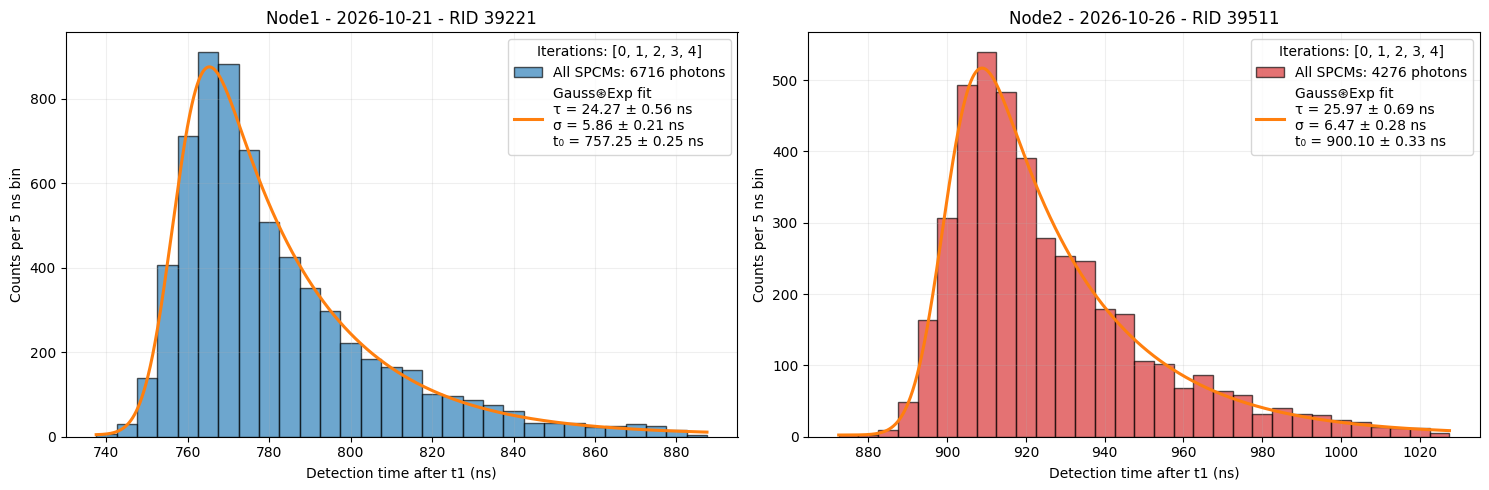

In [16]:
### Settings
### None combines every iteration: the arrival-time distribution is the same
### physics at every scan point, so pooling is what gives the histogram and its
### fit their statistics. Select iterations only when the scan variable itself
### moves the arrival time.
iterations_to_combine = {'Node1': None, 'Node2': None}
hist_bin_ns = 5  ### whole ns: the arrival times are whole ns
t0_guess = {'Node1': None, 'Node2': None}  ### None starts the fit at the histogram peak
sigma_guess = 5.0
tau_guess = 24.0

### Added to each detector's timestamps before combining (whole ns).
### Negative shift moves a delayed detector earlier. The same four SPCMs record
### both nodes' photons, so the same corrections apply to both runs. In
### 39221/38894 SPCM0_OtherNode arrives ~7 ns and SPCM1_OtherNode ~4 ns earlier
### than SPCM0/SPCM1: that cancels in the Node1-Node2 delay, but widens each
### node's combined σ.
SPCM_time_shifts_ns = {'SPCM0': 0.0, 'SPCM1': 0.0, 'SPCM0_OtherNode': 0.0, 'SPCM1_OtherNode': 0.0}

if any(shift != np.round(shift) for shift in SPCM_time_shifts_ns.values()): print('WARNING: use whole-ns detector shifts; the arrival times and histogram bins are whole ns.')
if hist_bin_ns != int(hist_bin_ns): print('WARNING: use a whole-ns hist_bin_ns; the arrival times are whole ns, so a fractional bin width puts them on bin edges.')

runs = {'Node1': run_Node1, 'Node2': run_Node2}
arrival = {}

for node, run in runs.items():
    node_iterations = iterations_to_combine[node] if isinstance(iterations_to_combine, dict) else iterations_to_combine
    node_t0_guess = t0_guess[node] if isinstance(t0_guess, dict) else None  ### one guess cannot fit both nodes, which are ~150 ns apart
    times, used_iterations = combine_all_SPCMs(run, node_iterations, SPCM_time_shifts_ns)
    arrival[node] = fit_arrival_histogram(times, hist_bin_ns, node_t0_guess, sigma_guess, tau_guess)
    arrival[node]['iterations'] = used_iterations
    arrival[node]['rid'] = run['rid']

    t0_fit, A_fit, sigma_fit, tau_fit, B_fit = arrival[node]['popt']
    t0_err, A_err, sigma_err, tau_err, B_err = arrival[node]['perr']
    gate_start = run['gate_start_offset_mu']
    gate_stop = gate_start+run['t_photon_collection_time']/1e-9
    window = arrival[node]['window']
    edge_margin = (t0_fit-window[0])/sigma_fit

    n_binned = arrival[node]['counts'].sum()
    print(f"{node} RID {run['rid']}: {len(times)} photons, iterations {used_iterations}" + (f" ({n_binned} in whole bins; the rest fall in a last, partial bin that is left out)" if n_binned != len(times) else ''))
    print(f"    recorded between {window[0]:.0f} and {window[1]:.0f} ns after t1 (gate set to t1+{gate_start:.0f} .. t1+{gate_stop:.0f} mu)")
    print(f"    Gauss⊛Exp fit: τ = {tau_fit:.2f} ± {tau_err:.2f} ns, σ = {sigma_fit:.2f} ± {sigma_err:.2f} ns, t₀ = {t0_fit:.2f} ± {t0_err:.2f} ns, B = {B_fit:.2f} ± {B_err:.2f}, peak at {arrival[node]['t_peak']:.1f} ns, χ²/dof = {arrival[node]['chi2_red']:.2f}")

    ### A gate that opened after the pulse began records only a falling tail, which matches the other node's
    ### tail at a wrong delay; the delay cell refuses to call such a result reliable
    arrival[node]['pulse_recorded'] = edge_margin >= 1 and sigma_err < 0.5*sigma_fit and tau_err < 0.5*tau_fit
    if not arrival[node]['pulse_recorded']: print(f"    WARNING: {node}'s photon pulse is not resolved (t₀ only {edge_margin:.1f} σ after the first recorded time, σ = {sigma_fit:.1f} ± {sigma_err:.1f} ns, τ = {tau_fit:.1f} ± {tau_err:.1f} ns): its gate missed the rising edge or recorded no pulse, so its arrival time and the delay below are NOT reliable.")
    elif edge_margin < 3: print(f"    note: the gate opened only {edge_margin:.1f} σ before t₀, so part of the rising edge was not recorded (the fit uses the recorded part)")

print(f"Runs differ in: gate {run_Node1['gate_start_offset_mu']}+{run_Node1['t_photon_collection_time']/1e-9:.0f} vs {run_Node2['gate_start_offset_mu']}+{run_Node2['t_photon_collection_time']/1e-9:.0f} mu, "
      f"excitation RF {run_Node1.get('p_GRIN2_excitation')} vs {run_Node2.get('p_GRIN2_excitation')} dBm, dates {run_Node1['date']} vs {run_Node2['date']}")

### Plot
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for ax, (node, result) in zip(axs, arrival.items()):
    t0_fit, A_fit, sigma_fit, tau_fit, B_fit = result['popt']
    t0_err, A_err, sigma_err, tau_err, B_err = result['perr']
    fit_x = np.linspace(result['edges'][0], result['edges'][-1], 2000)
    ax.hist(result['times'], bins=result['edges'], color=NODE_COLORS[node], edgecolor='black', alpha=0.65, label=f"All SPCMs: {result['counts'].sum()} photons")
    ax.plot(fit_x, gauss_exp_conv(fit_x, *result['popt']), color='tab:orange', lw=2.2, label=f'Gauss⊛Exp fit\nτ = {tau_fit:.2f} ± {tau_err:.2f} ns\nσ = {sigma_fit:.2f} ± {sigma_err:.2f} ns\nt₀ = {t0_fit:.2f} ± {t0_err:.2f} ns')
    ax.set_title(f"{node} - {runs[node]['date']} - RID {runs[node]['rid']}")
    ax.set_xlabel('Detection time after t1 (ns)')
    ax.set_ylabel(f'Counts per {hist_bin_ns} ns bin')
    ax.legend(title=f"Iterations: {result['iterations']}")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Extra Node2 delay for the best overlap
The delay is found by moving Node2's arrival times and maximising the overlap Σ√(p₁p₂) of the two measured histograms (1 = identical shapes). For pure single photons, (Σ√(p₁p₂))² is the temporal overlap that limits their two-photon interference, so its maximum is the natural "best" delay. Only the time range both gates recorded after the move is compared, so a gate that cut one node's rising edge or tail does not count as a shape difference. The ± is statistical, from resampling the photons (bootstrap).

Cross-checks: the delay that maximises the overlap of the two fitted pulse shapes (same criterion, without gate cuts, background or counting noise), the difference of the fitted t₀, and the peak-to-peak distance. The last two move away from the overlap maximum when the two pulses have different widths. All of them agree to about 1 ns, which changes the overlap by less than 0.1%, so the whole-ns value is the one to use.

Best extra delay for Node2: Δ = -143 ns (whole mu)
    histogram-overlap maximum at -143.0 ± 0.3 ns (statistical, 300 bootstrap resamples)
    cross-checks: fitted-shape overlap maximum at -142.9 ns, t₀(Node1) - t₀(Node2) = -142.8 ± 0.4 ns, peak-to-peak -143.6 ns
    overlap at Δ = -143 ns: 0.995 from the histograms (lowered by counting noise), 0.9991 from the fitted shapes (their best, 0.9991, is at -142.9 ns)

Node2's photons arrive 143 ns AFTER Node1's, relative to each run's t1 (the FORT switch-off in the excitation DMA).
    Of Δ = -143 ns, -100 ns come from the runs' different t_excitation_offset_mu (Node1 -330, Node2 -230) and -43 ns from Node2's excitation-to-detection latency being 43 ns longer than Node1's (it includes the satellite's DRTIO offset).
    To overlap them, shift Node2's whole excitation block (FORT switch-off and excitation pulse together) by -143 ns relative to Node1's (negative = earlier), or Node1's by +143 ns. Changing t_excitation_offset_mu alone also moves

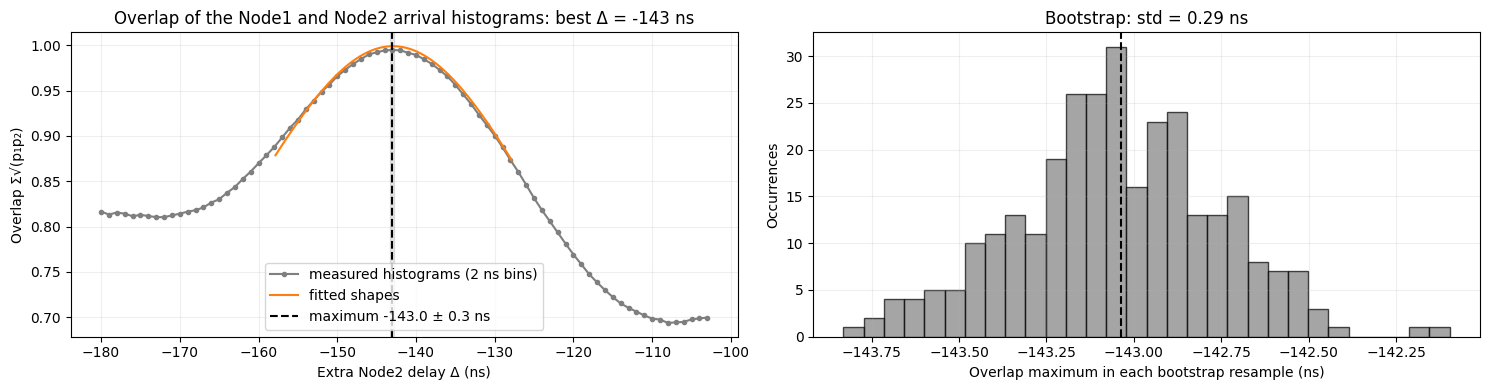

In [17]:
### Settings
overlap_bin_ns = 2  ### whole ns
delay_search_half_range_ns = 40  ### search this far either side of the fitted t₀ difference
min_common_fraction = 0.5  ### skip delays where the two gates share less than this fraction of either node's photons
n_bootstrap = 300

if overlap_bin_ns != int(overlap_bin_ns): print('WARNING: use a whole-ns overlap_bin_ns; the arrival times are whole ns, so a fractional bin width puts them on bin edges.')
for node, run in [('Node1', run_Node1), ('Node2', run_Node2)]:
    if arrival[node].get('rid') != run['rid']: raise RuntimeError(f"The {node} histogram is from RID {arrival[node].get('rid')}, but run_{node} is RID {run['rid']}. Re-run the 'Photon Arrival Histogram' cell first.")

rng = np.random.default_rng(0)
result1, result2 = arrival['Node1'], arrival['Node2']
times1, window1 = result1['times'], result1['window']
times2, window2 = result2['times'], result2['window']

### Cross-check: difference of the fitted t0
delay_t0 = result1['popt'][0]-result2['popt'][0]
delay_t0_err = np.hypot(result1['perr'][0], result2['perr'][0])

### Best overlap of the measured histograms: whole-ns steps, then a parabola through the top
delays = np.arange(np.round(delay_t0)-delay_search_half_range_ns, np.round(delay_t0)+delay_search_half_range_ns+1)
overlaps = overlap_vs_delay(times1, window1, times2, window2, delays, overlap_bin_ns, min_common_fraction)
if not np.any(np.isfinite(overlaps)): raise ValueError(f"No delay within ±{delay_search_half_range_ns} ns of the fitted t₀ difference ({delay_t0:.0f} ns) lets the two recorded gates share {min_common_fraction:.0%} of each node's photons. Check in the histograms above that both gates recorded the photon pulse; otherwise lower min_common_fraction or widen delay_search_half_range_ns.")
best_delay = refine_peak(delays, overlaps)
best_delay_whole = float(np.round(best_delay))

### Bootstrap: resample each node's photons and repeat the search near the best delay
near_delays = np.arange(best_delay_whole-8, best_delay_whole+9)
bootstrap_delays = []
for b in range(n_bootstrap):
    resampled1 = rng.choice(times1, size=len(times1), replace=True)
    resampled2 = rng.choice(times2, size=len(times2), replace=True)
    bootstrap_delays.append(refine_peak(near_delays, overlap_vs_delay(resampled1, window1, resampled2, window2, near_delays, overlap_bin_ns, min_common_fraction)))
bootstrap_delays = np.array(bootstrap_delays)
if np.any(np.isnan(bootstrap_delays)): print(f"WARNING: {np.count_nonzero(np.isnan(bootstrap_delays))} of {n_bootstrap} bootstrap resamples found no valid delay.")
best_delay_err = float(np.nanstd(bootstrap_delays, ddof=1))

### Cross-check: best overlap of the fitted pulse shapes (no background, no gate)
def fitted_pulse(t, popt): return gauss_exp_conv(t, popt[0], 1.0, popt[2], popt[3], 0.0)
shape_t = np.arange(result1['popt'][0]-150, result1['popt'][0]+600, 0.05)
shape1 = fitted_pulse(shape_t, result1['popt'])
shape1 = shape1/shape1.sum()
shape_delays = np.arange(delay_t0-15, delay_t0+15, 0.01)
shape_overlaps = []
for d in shape_delays:
    shape2 = fitted_pulse(shape_t-d, result2['popt'])
    shape_overlaps.append(np.sum(np.sqrt(shape1*shape2/shape2.sum())))
shape_overlaps = np.array(shape_overlaps)
delay_shape = shape_delays[np.argmax(shape_overlaps)]
shape_overlap_at_best = float(np.interp(best_delay_whole, shape_delays, shape_overlaps))

delay_peak = result1['t_peak']-result2['t_peak']
overlap_best = histogram_overlap(times1, window1, times2+best_delay_whole, (window2[0]+best_delay_whole, window2[1]+best_delay_whole), overlap_bin_ns, min_common_fraction)
reliable = result1['pulse_recorded'] and result2['pulse_recorded'] and abs(best_delay-delay_t0) <= max(3*np.hypot(best_delay_err, delay_t0_err), 3.0)

print(f"Best extra delay for Node2: Δ = {best_delay_whole:.0f} ns (whole mu)")
print(f"    histogram-overlap maximum at {best_delay:.1f} ± {best_delay_err:.1f} ns (statistical, {n_bootstrap} bootstrap resamples)")
print(f"    cross-checks: fitted-shape overlap maximum at {delay_shape:.1f} ns, t₀(Node1) - t₀(Node2) = {delay_t0:.1f} ± {delay_t0_err:.1f} ns, peak-to-peak {delay_peak:.1f} ns")
print(f"    overlap at Δ = {best_delay_whole:.0f} ns: {overlap_best:.3f} from the histograms (lowered by counting noise), {shape_overlap_at_best:.4f} from the fitted shapes (their best, {shape_overlaps.max():.4f}, is at {delay_shape:.1f} ns)")
if not reliable: print(f"WARNING: NOT RELIABLE - a node's pulse is not resolved (see the histogram cell) or the histogram delay ({best_delay:.1f} ns) and the t₀ difference ({delay_t0:.1f} ns) disagree. Do not use the numbers below.")
print()

offset_difference = run_Node1['t_excitation_offset_mu']-run_Node2['t_excitation_offset_mu']
if best_delay_whole < 0: print(f"Node2's photons arrive {-best_delay_whole:.0f} ns AFTER Node1's, relative to each run's t1 (the FORT switch-off in the excitation DMA).")
elif best_delay_whole > 0: print(f"Node2's photons arrive {best_delay_whole:.0f} ns BEFORE Node1's, relative to each run's t1 (the FORT switch-off in the excitation DMA).")
else: print("Node2's and Node1's photons already arrive together, relative to each run's t1.")
latency_difference = best_delay_whole-offset_difference
print(f"    Of Δ = {best_delay_whole:+.0f} ns, {offset_difference:+.0f} ns come from the runs' different t_excitation_offset_mu (Node1 {run_Node1['t_excitation_offset_mu']}, Node2 {run_Node2['t_excitation_offset_mu']}) "
      f"and {latency_difference:+.0f} ns from Node2's excitation-to-detection latency being {abs(latency_difference):.0f} ns {'longer' if latency_difference < 0 else 'shorter'} than Node1's (it includes the satellite's DRTIO offset).")
print(f"    To overlap them, shift Node2's whole excitation block (FORT switch-off and excitation pulse together) by {best_delay_whole:+.0f} ns relative to Node1's (negative = earlier), or Node1's by {-best_delay_whole:+.0f} ns. "
      f"Changing t_excitation_offset_mu alone also moves the pulse relative to that node's own FORT switch-off.")
print(f"    After the shift both photons peak near t1+{result1['t_peak']:.0f} ns; the four shared SPCMs then need one gate, and Node1's (recording from {window1[0]:.0f} ns) "
      f"opens {(result2['popt'][0]+best_delay_whole-window1[0])/result2['popt'][2]:.1f} σ before Node2's shifted t₀.")

### Plot the overlap against the delay
fig, axs = plt.subplots(1, 2, figsize=(15, 4))
axs[0].plot(delays, overlaps, 'o-', color='tab:gray', ms=3, label=f'measured histograms ({overlap_bin_ns} ns bins)')
axs[0].plot(shape_delays, shape_overlaps, color='tab:orange', lw=1.5, label='fitted shapes')
axs[0].axvline(best_delay, color='black', ls='--', label=f'maximum {best_delay:.1f} ± {best_delay_err:.1f} ns')
axs[0].axvspan(best_delay-best_delay_err, best_delay+best_delay_err, color='black', alpha=0.1)
axs[0].set_xlabel('Extra Node2 delay Δ (ns)')
axs[0].set_ylabel('Overlap Σ√(p₁p₂)')
axs[0].set_title(f'Overlap of the Node1 and Node2 arrival histograms: best Δ = {best_delay_whole:.0f} ns')
axs[0].legend(loc='lower center')
axs[0].grid(alpha=0.2)

axs[1].hist(bootstrap_delays[np.isfinite(bootstrap_delays)], bins=30, color='tab:gray', edgecolor='black', alpha=0.7)
axs[1].axvline(best_delay, color='black', ls='--')
axs[1].set_xlabel('Overlap maximum in each bootstrap resample (ns)')
axs[1].set_ylabel('Occurrences')
axs[1].set_title(f'Bootstrap: std = {best_delay_err:.2f} ns')
axs[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Node1 and Node2 arrival histograms with the best delay

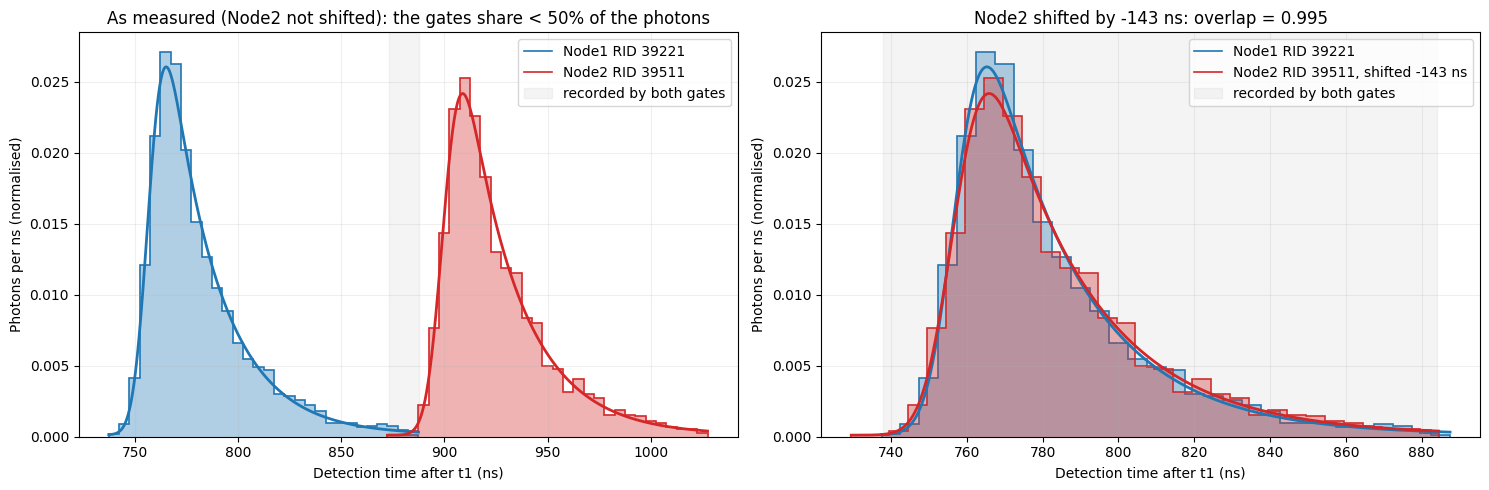

In [18]:
### None plots with the best whole-ns delay found above; set a number (ns) to try another one
Node2_delay_to_plot_ns = None

result1, result2 = arrival['Node1'], arrival['Node2']
times1, window1, times2, window2 = result1['times'], result1['window'], result2['times'], result2['window']
delay_to_plot = best_delay_whole if Node2_delay_to_plot_ns is None else Node2_delay_to_plot_ns
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

for ax, delay in zip(axs, [0.0, delay_to_plot]):
    common_start = max(window1[0], window2[0]+delay)
    common_stop = min(window1[1], window2[1]+delay)
    for node, result, shift in [('Node1', result1, 0.0), ('Node2', result2, delay)]:
        ### each histogram normalised to its own photon number, so the two nodes compare despite different counts
        density = result['counts']/(result['counts'].sum()*result['bin_ns'])
        label = f"{node} RID {runs[node]['rid']}" + (f", shifted {shift:+g} ns" if shift else '')
        ax.stairs(density, result['edges']+shift, fill=True, color=NODE_COLORS[node], alpha=0.35)
        ax.stairs(density, result['edges']+shift, color=NODE_COLORS[node], lw=1.2, label=label)
        fit_x = np.linspace(result['edges'][0], result['edges'][-1], 2000)
        ax.plot(fit_x+shift, gauss_exp_conv(fit_x, *result['popt'])/(result['counts'].sum()*result['bin_ns']), color=NODE_COLORS[node], lw=2)
    title = 'As measured (Node2 not shifted)' if delay == 0 else f'Node2 shifted by {delay:+g} ns'
    if common_stop > common_start:
        ax.axvspan(common_start, common_stop, color='tab:gray', alpha=0.08, label='recorded by both gates')
        overlap = histogram_overlap(times1, window1, times2+delay, (window2[0]+delay, window2[1]+delay), overlap_bin_ns, min_common_fraction)
        title += f': overlap = {overlap:.3f}' if np.isfinite(overlap) else f': the gates share < {min_common_fraction:.0%} of the photons'
    elif delay != 0:
        title += ': the two gates share no time range'
    ax.set_title(title)
    ax.set_xlabel('Detection time after t1 (ns)')
    ax.set_ylabel('Photons per ns (normalised)')
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()